# 19 · QUOTA: the model and its interpretation on every benchmark

**QUOTA** (*Qubit Utilization thrOugh Trained Allocation*) is a hybrid physics world model: a pretrained classical trunk does the part it does well (the *digital* part), and small Rydberg registers work only on the part it gets wrong (the *analog* part), at places chosen per input. This notebook shows

1. **the model**: backbone, neck and head, the two quantum insertion points, and the register itself;
2. **the theory** it is built on (machine-checked in Lean 4);
3. **where every benchmark stands** against its state of the art;
4. **per-benchmark interpretation**: where the trunk's error lives, where the atoms go, what the trained register learned, and whether it beats its matched classical twin;
5. the benchmarks outside the allocation study (Sophelio, TokaMark, TORAX, TDC);
6. the analog-vs-digital probe; 7. the synthesis.

All numbers come from result files in `runs/`; interpretation models are seed-1 refits at each row's validation-best strategy (`paper/alloc/interp.py`). Everything is classically simulated (≤10 atoms per register); nothing here is a quantum-advantage claim.

In [1]:

import sys, pathlib, json, re, warnings
warnings.filterwarnings('ignore')
ROOT = pathlib.Path().resolve().parent
for p in ('paper', 'paper/alloc', 'paper/phase_b', 'paper/geothermal'):
    sys.path.insert(0, str(ROOT / p))
import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt
pd.set_option('display.precision', 4); pd.set_option('display.max_colwidth', 110); pd.set_option('display.width', 200)
plt.rcParams['figure.dpi'] = 100
import nbviz, interp, analyze
print('GPU:', torch.cuda.get_device_name(0))


GPU: NVIDIA GB10


## 1. The model: backbone, neck, head

Every trunk is split into three slots. The **backbone** encodes the input history; the **neck** is the deepest, lowest-resolution representation; the **head** decodes to the predicted fields. QUOTA inserts a register at two places:

* **in the neck (the audit insertion):** mean-pool the neck features, run a 3×10-atom register on the pooled vector, and broadcast a zero-initialized gated correction back. It starts exactly at the released model, but it can only read and write the spatial DC mode (Lean `pool_blind`).
* **after the head (the routed co-processor):** write the trunk's residual in an orthonormal Haar basis, let an allocation rule pick K tiles per input, place one atom per tile (x, y from position, z from scale), and write a correction back to exactly those tiles. The trunk is frozen; the corrected error is exact from coefficients.

The matched classical control uses the identical boxes with the register replaced by a parameter-matched MLP.

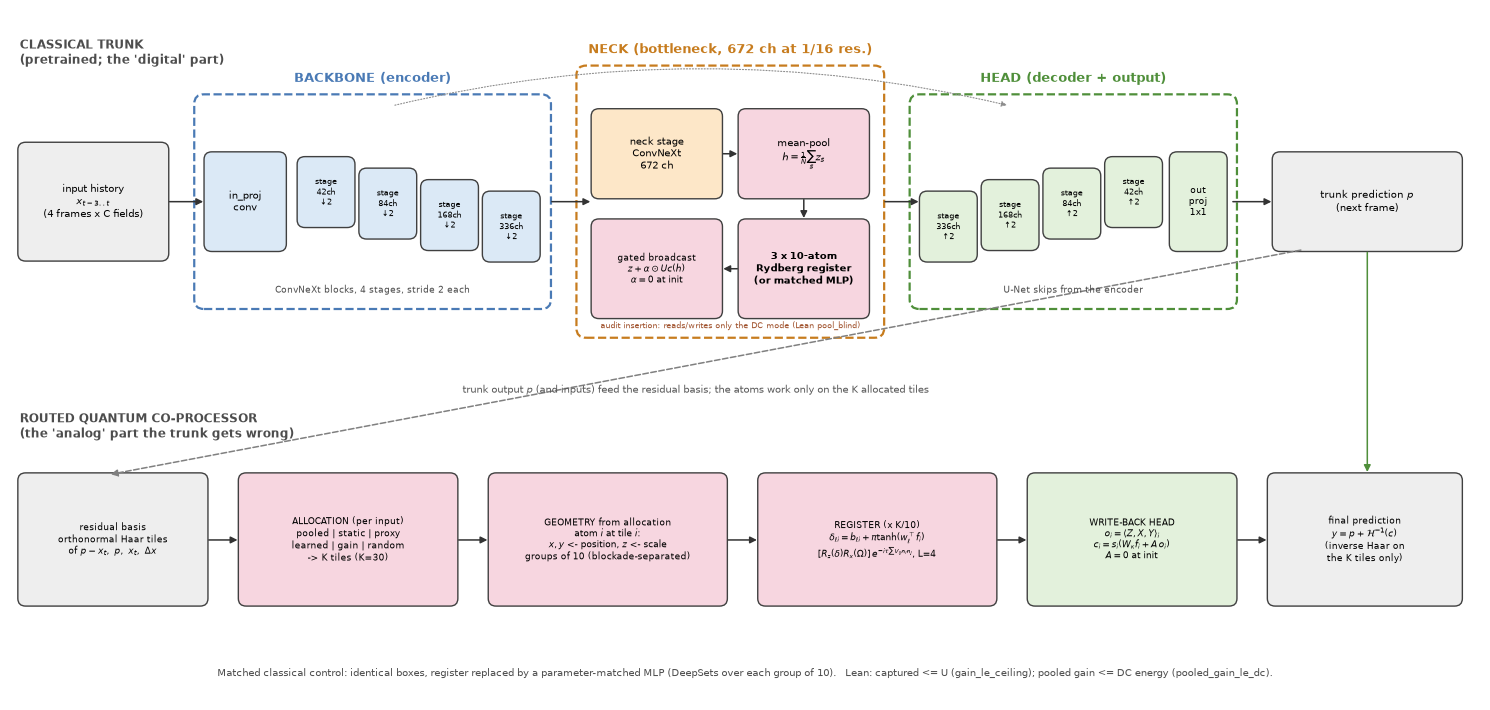

In [2]:
nbviz.architecture(); plt.show()

### 1.1 Backbone, neck and head of every benchmark

In [3]:
display(nbviz.backbone_table())

,benchmark,backbone,neck (quantum insertion),head,weights
0,TRL2D (The Well),"CNextU-net: in_proj + 4 ConvNeXt encoder stages (42->336 ch, /16)",bottleneck stage 672 ch at 8x24; pooled register (audit) or none (frozen study),4 decoder stages with skips + 1x1 out_proj -> 4 fields; routed co-processor on the residual,polymathic-ai UNetConvNext (released)
1,rayleigh_benard,"CNextU-net (same family), 512x128",bottleneck stage; pooled register,decoder + out_proj; routed co-processor,released
2,shear_flow,"CNextU-net, 256x512",bottleneck stage; pooled register,decoder + out_proj; routed co-processor,released (does not reproduce its published number)
3,MHD_64,"3-D CNextU-net, 64^3, 7 fields",bottleneck stage; pooled register,decoder + out_proj; routed co-processor (3-D Haar),released (does not reproduce)
4,RealPDEBench airfoil,"RealPDEBench U-Net / FNO (20->20 frames, 64x128)",none (trunk frozen),low-mode Fourier corrector (register or MLP core) or routed Haar co-processor,RealPDEBench released checkpoints
5,Pelzer 1HP heat plume,"1HP_NN U-Net (depth 3, 32 feat.)",deepest encoder (256 ch at 32x2); pooled register,decoders + conv head -> temperature; routed co-processor,trained by us with the 1HP_NN recipe
6,Sophelio Ch1 (DIII-D),residual MLP over magnetics (14 lags) + Thomson features,"latent coupling: register on the 1-D latent, or routed coupling writing PCA components k>=8","PCA-64 flux decoder + scalar heads (q95, betaN, li, R, Z)","NAS-selected trunks, 7-member ensemble"
7,TokaMark 1-1 (MAST),TokaMind-Base-v2 transformer (CLS latent),"register wraps every modality head input (vector latent, no pooling)",TokaMind modality heads,UKAEA/IBM TokaMind-Base-v2 (released)
8,TORAX-Bench,1-D spectral net: lift + 2 spectral blocks (27-cell rho grid),mid slot (Bottleneck); pooled register,2 spectral blocks + projection; delta prediction,trained by us
9,TDC ADMET (22 endpoints),CheMeleon D-MPNN foundation model (+ MapLight / GIN features),register after mean aggregation (molecule embedding),FFN property head; VALID-selected stack with MapLight(+GNN) CatBoost,CheMeleon released weights


### 1.2 Live: the released CNextU-net split into its slots, and the register in its neck

Parameter counts per slot for each released Well checkpoint, then the TRL2D hybrid: the neck is wrapped with the gated bottleneck; with α = 0 the hybrid reproduces the released model exactly (checked on the GPU).

In [4]:
from cnext_hybrid import load_official, build_hybrid
rows = {}
for name, d in [('TRL2D', 'data/cnext_ckpt'), ('rayleigh_benard', 'data/cnext_rb_ckpt'), ('shear_flow', 'data/cnext_shear_flow_ckpt'), ('MHD_64 (3-D)', 'data/cnext_mhd_ckpt')]:
    mdl, cfg = load_official(str(ROOT / d)); rows[name] = {**nbviz.cnext_parts(mdl), 'total': nbviz.count(mdl)}
display(pd.DataFrame(rows).T)
base = build_hybrid('vanilla').cuda().eval(); hyb = build_hybrid('mr30ryd').cuda().eval(); mlp = build_hybrid('mlp30').cuda().eval()
bq, bm = hyb.neck.bottleneck, mlp.neck.bottleneck
print(f'neck insertion: register core {nbviz.count(bq.core):,} params (+ up-projection {nbviz.count(bq.up):,}, gate {bq.alpha.numel()}); '
      f'matched MLP core {nbviz.count(bm.core):,}')
x = torch.randn(1, 16, 128, 384, device='cuda')
with torch.no_grad(): print('zero-init identity, max |hybrid - released| =', float((hyb(x) - base(x)).abs().max()))

,backbone (in_proj + encoder),neck (bottleneck stage),head (decoder + out_proj),total
TRL2D,3680250,3651648,11243446,18575344
rayleigh_benard,3680250,3651648,11243446,18575344
shear_flow,3680250,3651648,11243446,18575344
MHD_64 (3-D),5275914,3849216,13190275,22315405


neck insertion: register core 161,844 params (+ up-projection 20,832, gate 672); matched MLP core 161,720


zero-init identity, max |hybrid - released| = 0.0


### 1.3 The register close-up

Each register is 10 atoms under $H/\hbar = \sum_i \tfrac{\Omega_\ell}{2}X_i - \sum_i \delta_{\ell,i} n_i + \sum_{i<j} C_6 |r_i-r_j|^{-6} n_i n_j$, simulated exactly as $L=4$ layers of per-atom $R_z(\delta)R_x(\Omega)$ followed by the interaction phase. Detunings encode the tile features; positions come from the allocation, so the interaction graph changes with every input. Below: one trained register on a real heat-plume test input.

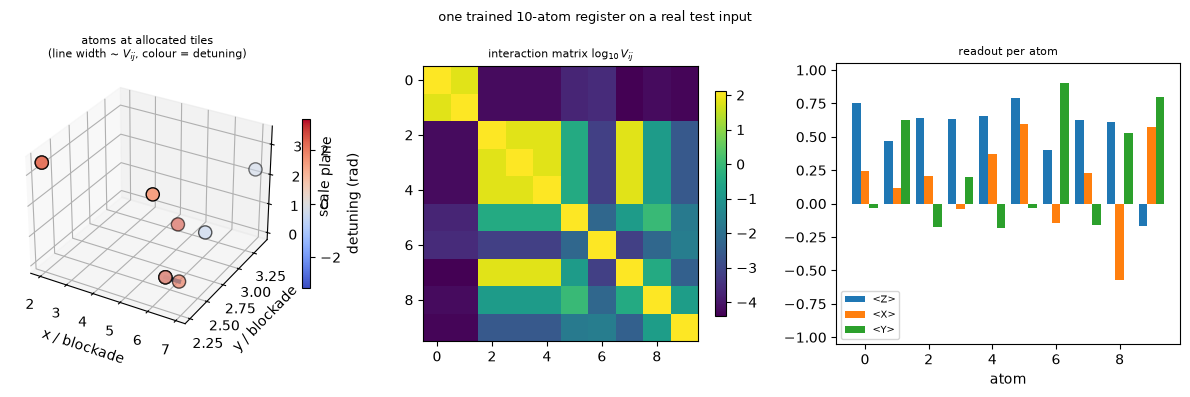

,ryd,gutz,ryd2d,mlp,mlpX4,hyb,mlp2
core parameters (F=25 features),156,156,156,165,651,321,330


In [5]:
run, m, st, d = interp.load('pelzer', 'ryd')
pos, V, det, o = interp.one_group(run, m, st)
nbviz.register_closeup(pos, V, det, o); plt.show()
from cores import make_tile_core, n_params
F = run.fz.F
display(pd.Series({k: n_params(make_tile_core(k, F)) for k in ['ryd', 'gutz', 'ryd2d', 'mlp', 'mlpX4', 'hyb', 'mlp2']}, name=f'core parameters (F={F} features)').to_frame().T)

## 2. The theory (machine-checked in Lean 4, standard axioms only)

* `pool_blind`, `broadcast_orthogonal`: a pooled insertion reads and writes only the DC mode, whatever its core.
* `residual_after_band_removal`, **`gain_le_ceiling`**: a correction supported on a component set removes at most the error energy there, so the captured share never exceeds the utilization ceiling U.
* **`ceiling_mono`**: nested allocations have nested ceilings; **`pooled_gain_le_dc`**: a broadcast correction removes at most $(\sum_i e_i)^2/n$, however many atoms produced it.
* `swap_improves`: under a budget, top-K by gain is optimal.

These prove **where** atoms must work. They do not prove that atoms do the job better than a classical core; that is tested empirically below. The cell lists the theorems and checks two of them numerically.

In [6]:
for f in sorted((ROOT / 'formal' / 'QuotaScaling').glob('*.lean')):
    print(f'{f.name:22s}', ', '.join(re.findall(r'^theorem (\w+)', f.read_text(), re.M)))
g = torch.Generator().manual_seed(0); e = torch.randn(10000, 64, generator=g)
c = e.mean(1, keepdim=True) * torch.rand(10000, 1, generator=g) * 2
print('pooled_gain_le_dc holds on 10k random fields:', bool(((e**2).sum(1) - ((e - c)**2).sum(1) <= e.sum(1)**2 / 64 + 1e-4).all()))
Q = torch.linalg.qr(torch.randn(64, 64, generator=g))[0]; a = torch.randn(10000, 8, generator=g)
coef = e @ Q; corr = torch.zeros_like(coef); corr[:, :8] = a
print('gain_le_ceiling holds:', bool(((e**2).sum(1) - ((coef - corr)**2).sum(1) <= (coef[:, :8]**2).sum(1) + 1e-4).all()))

Basic.lean             utilization_nonneg, utilization_lt_one, utilization_mono, classical_limit, zero_gain, gain_identity, error_nonneg, error_antitone_in_use, nonpositive_gain_no_benefit, utilization_increment, allocation_bound, independent_registers_linear, register_width_doubles, thirty_qubit_accounting, monolithic_thirty
Routing.lean           correction_abs_bound, zero_gate, zero_allocation, token_energy_bound, active_qubit_cap
SpectralRouting.lean   pool_blind, mode_zero_mean, pool_blind_mode, broadcast_orthogonal, band_energy_split, coeff_after_removal, residual_after_band_removal, total_eq, pointwise_min_optimal, swap_improves, swap_card, reupload_degree, vdw_hasDerivAt, vdw_sensitivity_anti, lattice_sep, dip_inplane, dip_axial, dip_magic
Utilization.lean       coeff_of_correction, gain_le_ceiling, ceiling_mono, pooled_gain_le_dc
pooled_gain_le_dc holds on 10k random fields: True
gain_le_ceiling holds: True


## 3. Where every benchmark stands against its state of the art

In [7]:
display(nbviz.sota_table())

,benchmark,published best,our best,vs SoTA,register's role
0,TRL2D one-step VRMSE,CNextU-net 0.1956 (released re-eval 0.1934),0.1929 (3-seed ensemble),at SoTA,none: every arm 0.1929-0.1930
1,TRL2D rollout 13:30,CNextU-net 1.01,0.9528 (TD fine-tune + register),-6% (better),"register-specific: MLP 1.032, trunk 1.030"
2,RealPDEBench foil rel. L2,released U-Net 0.00948,0.00931 (low-mode corrector + ensemble),-1.8% (better),register corrector 0.00939 = MLP
3,rayleigh_benard VRMSE,TFNO 0.6566,"0.4563 (fine-tuned trunk, full test)",-30% (better),"register arm 0.4221, n.s."
4,Fusion Equilibrium Ch1 S,0.9932,0.9910 (single TEST scoring),-0.0022 (below),register-coupled ensemble 0.9905
5,TokaMark 1-1 NRMSE,TokaMind-Scratch 0.140,0.1454,below,register 0.1501 vs MLP 0.1504
6,TDC ADMET (21 scored),per-endpoint leaders,"classical stack #1 on 7, top-3 on 15-16",partial,register stack #1 on 6; register < MLP on 13/22
7,MHD_64 VRMSE,0.1633,released ckpt 0.5447 on our evaluator,no fair comparison,tie
8,shear_flow VRMSE,0.8080,released ckpt 0.9946 on our evaluator,no fair comparison,tie
9,Pelzer 1HP MAE,"0.046 C (unverifiable, dropped)",0.0291 C,n/a,tie


The matched-control audit (pooled register in the neck, fine-tuned, three seeds; `runs/judge/scorecard.json`):

In [8]:
display(nbviz.audit_rows().round(4))

,row,tier,trunk,matched MLP,register,register vs MLP %,p
0,TRL2D arena VRMSE@8,primary,0.9567,0.9534,0.8447,11.3967,0.1599
1,MHD_64 VRMSE,primary,0.1897,0.1897,0.1896,0.0362,0.2751
2,"MHD_64 VRMSE, all seeds (unequal training length)",secondary,0.1855,0.1938,0.1856,4.2464,0.4194
3,rayleigh_benard VRMSE,primary,0.4563,0.5275,0.4221,19.9911,0.0726
4,shear_flow VRMSE,primary,0.2686,0.2539,0.2659,-4.7459,0.8457
5,TORAX-Bench VRMSE@8 (tuned),primary,0.0158,0.0141,0.0168,-19.2367,0.3992
6,Pelzer 1HP MAE °C (tuned),primary,0.0291,0.0292,0.0288,1.3183,0.4380
7,Sophelio S (tuned),primary,0.7905,0.7848,0.7929,1.0394,0.4562
8,TokaMark 1-1 NRMSE (TokaMind trunk),primary,0.1509,0.1504,0.1501,0.1690,0.6311
9,TORAX-Bench VRMSE@8 (fixed),secondary,0.0321,0.0295,0.0292,1.0629,0.9236


## 4. Per-benchmark interpretation (allocation study, frozen trunks)

For each row: the utilization ceilings of each allocation rule; where the 30 atoms go on one test window and at which scales; the strategy × core table (test gain, captured share, efficiency = captured / U); qubits vs utilization; the trained register's corrections against the true residual; the controls; and a look inside the trained register (learned blockade scale and drives, which observables it uses, how much of the correction it carries, and how entangled it is on real inputs).

### 4.1 The Well TRL2D: turbulent radiative layer (headline row)

**Backbone/neck/head:** released CNextU-net (encoder 42→336 ch; neck 672 ch at 8×24; decoder + 1×1 head, 4 fields). **Quantum:** pooled register in the neck (audit and TD fine-tuning), routed co-processor after the head (frozen study).

utilization ceilings (share of the trunk error energy reachable by each rule):


,proxy@30,static@30,random@30,oracle@10,oracle@30,oracle@100,oracle@300,dc
U,0.1719,0.2377,0.0006,0.2734,0.4448,0.6473,0.8019,0.0556


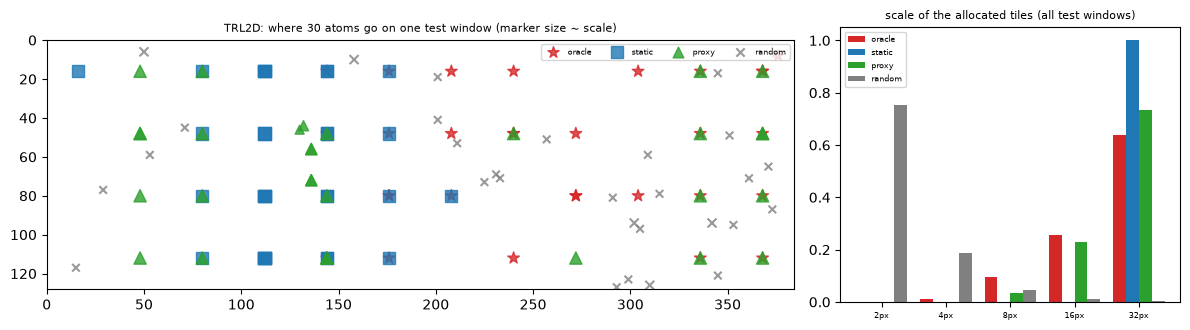

In [9]:
B = 'turbulent_radiative_layer_2D'
alloc = interp.allocation(B)
print('utilization ceilings (share of the trunk error energy reachable by each rule):')
display(pd.Series({k: v for k, v in alloc['ceil'].items() if k == 'dc' or k.endswith('@30') or k.startswith('oracle')}).round(4).to_frame('U').T)
nbviz.allocation_plot(alloc, B); plt.show()

,U,lin gain %,lin captured,mlp gain %,mlp captured,ryd gain %,ryd captured,efficiency ryd
strategy,,,,,,,,
pooled,0.0556,0.0613,0.0015,0.0553,0.0014,0.0606,0.0013,0.0236
static,0.2377,-0.0365,-0.0007,0.0000,0.0000,0.0000,0.0000,0.0000
proxy,0.1719,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
learned,0.2230,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
gain,0.0640,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
random,0.0006,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
oracle,0.4448,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


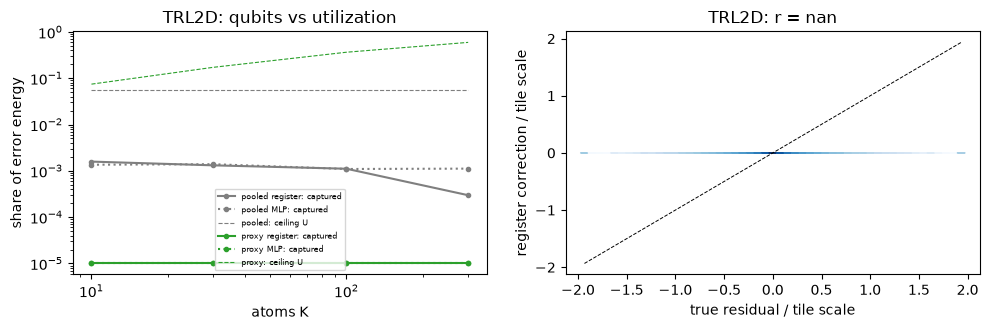

,register vs,strategy,rel. gain %,wins,p
0,mlp,static,0.0000,0/3,NaN
1,lin,static,0.0365,2/3,0.2607
2,gutz,static,0.0044,1/3,0.4226
3,ryd2d,static,0.0328,2/3,0.1847
4,mlpX4,static,0.0000,0/3,NaN
5,hyb vs mlp2 (division of labour),static,0.0201,2/3,0.6825


In [10]:
display(nbviz.row_table(B).round(4))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4)); nbviz.ksweep(B, ax[0])
run, m, st, d = interp.load(B, 'ryd'); x, y = interp.correction_vs_residual(run, m, st)
nbviz.scatter_corr(x, y, B, ax[1]); plt.tight_layout(); plt.show()
display(nbviz.controls(B).round(4))

In [11]:
print('best strategy (VALID):', st)
print('learned analog controls:', interp.register_physics(m))
print('readout usage (share of |A| per observable):', interp.readout_usage(m))
print('register path split:', {k: round(v, 4) for k, v in interp.path_split(run, m, st).items()})
print('entanglement of the trained register on test groups:', {k: round(v, 3) for k, v in interp.entanglement(run, m, st).items()})
run2, m2, _, _ = interp.load(B, 'mlp')
print('matched-MLP path split:', {k: round(v, 4) for k, v in interp.path_split(run2, m2, st).items()})

best strategy (VALID): static
learned analog controls: {'blockade_scale_px': [4.0, 4.0, 4.0], 'scale_plane_dz': 1.0, 'drive_omega': [0.5, 0.5, 0.5, 0.5], 'evolution_tau': [0.30000001192092896, 0.30000001192092896, 0.30000001192092896, 0.30000001192092896], 'detuning_weight_norm': 1.5801515579223633, 'base_detuning_spread': 0.0193290114402771}
readout usage (share of |A| per observable): {'Z': 0.0, 'X': 0.0, 'Y': 0.0}


/home/mohhakami/Documents/paper/quworld/paper/alloc/interp.py:92: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:822.)
  "detuning_weight_norm": float(r.w.weight.norm()),


register path split: {'core_energy_share': 0.0, 'captured_full': 0.0, 'captured_without_core': 0.0}
entanglement of the trained register on test groups: {'half_entropy_bits_mean': 0.208, 'half_entropy_bits_max': 0.732, 'single_atom_purity_mean': 0.963, 'nn_interaction_mean': 38.4, 'groups': 192}
matched-MLP path split: {'core_energy_share': 0.0, 'captured_full': 0.0, 'captured_without_core': 0.0}


**Interpretation.** Nothing the trunk gets wrong at fine scale is predictable from causal inputs: every tile strategy, every core and a 64× larger MLP capture zero, even with oracle placement (ceiling 44%). The pipeline is not the limit: fed the residual itself, the same co-processor captures 99.7% of the ceiling (VRMSE 0.194 → 0.150). The pooled insertion captures a sliver of its DC ceiling (+0.06%). The one register-specific effect on this row is training-mediated: under temporal-difference fine-tuning the register lowers long-horizon rollout error (0.953 vs 1.030 trunk, 1.032 MLP), and the band analysis below shows it acts only at wavenumber 0, as the pooling proposition requires.

**TRL2D spectral evidence (fine-tuned audit arms):** where the released checkpoint's error lives by wavenumber shell, and the register's effect per shell.

In [12]:
d = json.loads((ROOT / 'runs/spectral/trl2d_bands.json').read_text())
E = np.array(d['arms']['official']['E_err_k']); k = np.arange(len(E))
shells = {'0 (DC)': k == 0, '1-4': (k >= 1) & (k <= 4), '5-16': (k >= 5) & (k <= 16), '17-32': (k >= 17) & (k <= 32), '>=33': k >= 33}
def share(arm): E = np.array(d['arms'][arm]['E_err_k']); return {s: E[msk].sum() for s, msk in shells.items()}
base = {s: np.mean([share(f'vanilla_s{x}')[s] for x in (1337, 1338, 1339)]) for s in shells}
tab = pd.DataFrame({'error share (released)': {s: E[msk].sum() / E.sum() for s, msk in shells.items()},
    'register vs vanilla %': {s: 100 * (np.mean([share(f'mr30ryd_s{x}')[s] for x in (1337, 1338, 1339)]) / base[s] - 1) for s in shells},
    'MLP vs vanilla %': {s: 100 * (np.mean([share(f'mlp30_s{x}')[s] for x in (1337, 1338, 1339)]) / base[s] - 1) for s in shells}})
display(tab.round(3))
print('TD fine-tuning, TRL2D rollout VRMSE@13:30 (3 seeds): register 0.9528 | trunk 1.0301 | matched MLP 1.0322 | no-interaction 1.0156 | mean-field 1.0495')

,error share (released),register vs vanilla %,MLP vs vanilla %
0 (DC),0.029,-0.486,0.103
1-4,0.200,-0.150,0.003
5-16,0.428,-0.130,0.128
17-32,0.231,-0.178,0.149
>=33,0.111,-0.117,0.126


TD fine-tuning, TRL2D rollout VRMSE@13:30 (3 seeds): register 0.9528 | trunk 1.0301 | matched MLP 1.0322 | no-interaction 1.0156 | mean-field 1.0495


### 4.2 rayleigh_benard: convection (fission-proxy thermal hydraulics)

**Backbone/neck/head:** released CNextU-net (512×128, buoyancy, pressure, velocity). **Quantum:** pooled register in the neck (audit) and routed co-processor on the residual (study).

utilization ceilings (share of the trunk error energy reachable by each rule):


,proxy@30,static@30,random@30,oracle@10,oracle@30,oracle@100,oracle@300,dc
U,0.1605,0.1817,0.0004,0.1454,0.2915,0.4462,0.5576,0.0826


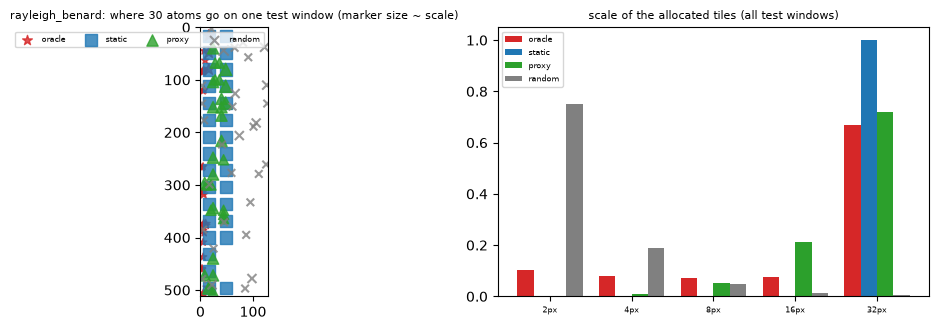

In [13]:
B = 'rayleigh_benard'
alloc = interp.allocation(B)
print('utilization ceilings (share of the trunk error energy reachable by each rule):')
display(pd.Series({k: v for k, v in alloc['ceil'].items() if k == 'dc' or k.endswith('@30') or k.startswith('oracle')}).round(4).to_frame('U').T)
nbviz.allocation_plot(alloc, B); plt.show()

,U,lin gain %,lin captured,mlp gain %,mlp captured,ryd gain %,ryd captured,efficiency ryd
strategy,,,,,,,,
pooled,0.0826,2.7520,0.0506,6.0047,0.0689,6.6929,0.0732,0.8855
static,0.1817,28.8237,0.1121,33.0169,0.1352,32.8581,0.1317,0.7253
proxy,0.1605,28.7461,0.0873,36.5533,0.1173,36.2488,0.1130,0.7042
learned,0.2296,28.0040,0.1299,36.2957,0.1691,34.4748,0.1603,0.6983
gain,0.2265,29.4648,0.1366,36.4748,0.1717,35.5503,0.1681,0.7421
random,0.0004,0.0035,-0.0007,0.0017,-0.0005,0.0037,-0.0005,-1.2180
oracle,0.2915,30.1880,0.1473,36.4830,0.1732,34.4472,0.1610,0.5523


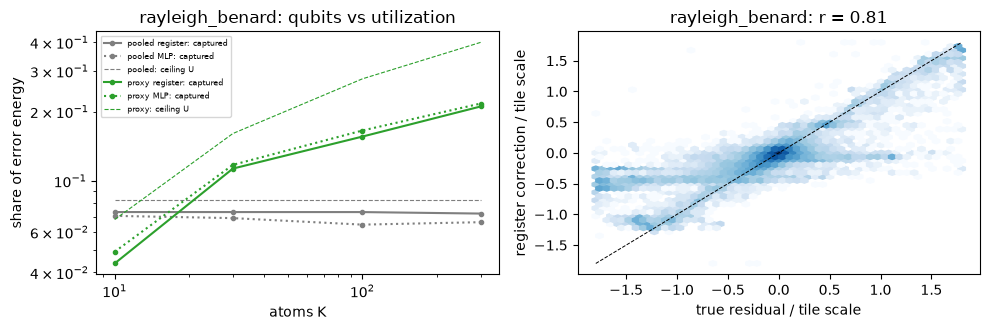

,register vs,strategy,rel. gain %,wins,p
0,mlp,proxy,-0.4795,1/3,0.3119
1,lin,proxy,10.5244,3/3,0.0025
2,gutz,proxy,6.7830,2/3,0.2210
3,ryd2d,proxy,1.6327,1/3,0.4323
4,mlpX4,proxy,-1.4042,0/3,0.0678
5,hyb vs mlp2 (division of labour),proxy,-0.4314,2/3,0.6466


In [14]:
display(nbviz.row_table(B).round(4))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4)); nbviz.ksweep(B, ax[0])
run, m, st, d = interp.load(B, 'ryd'); x, y = interp.correction_vs_residual(run, m, st)
nbviz.scatter_corr(x, y, B, ax[1]); plt.tight_layout(); plt.show()
display(nbviz.controls(B).round(4))

In [15]:
print('best strategy (VALID):', st)
print('learned analog controls:', interp.register_physics(m))
print('readout usage (share of |A| per observable):', interp.readout_usage(m))
print('register path split:', {k: round(v, 4) for k, v in interp.path_split(run, m, st).items()})
print('entanglement of the trained register on test groups:', {k: round(v, 3) for k, v in interp.entanglement(run, m, st).items()})
run2, m2, _, _ = interp.load(B, 'mlp')
print('matched-MLP path split:', {k: round(v, 4) for k, v in interp.path_split(run2, m2, st).items()})

best strategy (VALID): proxy
learned analog controls: {'blockade_scale_px': [3.609999895095825, 4.03000020980835, 4.0], 'scale_plane_dz': 0.5796080827713013, 'drive_omega': [-0.003000000026077032, 0.39100000262260437, -0.4519999921321869, -0.014000000432133675], 'evolution_tau': [0.257999986410141, 0.39500001072883606, 0.3490000069141388, 0.24199999868869781], 'detuning_weight_norm': 2.5029847621917725, 'base_detuning_spread': 0.06537306308746338}
readout usage (share of |A| per observable): {'Z': 0.0820000022649765, 'X': 0.492000013589859, 'Y': 0.4259999990463257}


register path split: {'core_energy_share': 0.1452, 'captured_full': 0.115, 'captured_without_core': 0.0246}
entanglement of the trained register on test groups: {'half_entropy_bits_mean': 0.0, 'half_entropy_bits_max': 0.013, 'single_atom_purity_mean': 1.0, 'nn_interaction_mean': 17.723, 'groups': 192}
matched-MLP path split: {'core_energy_share': 0.1382, 'captured_full': 0.1196, 'captured_without_core': -0.1253}


**Interpretation.** The released trunk's error is large and systematic at the convection onset (initial transient VRMSE ≈ 7). 30 routed atoms cut mean VRMSE by ~36% (median −4%, 94% of windows improve) against 6–7% for the pooled insertion. This is the one row where a nonlinear core matters (+~10% over the linear corrector), but the register and the matched MLP are equal; the mean-field register is within noise.

### 4.3 shear_flow: 2-D shear-layer turbulence

**Backbone/neck/head:** released CNextU-net (256×512). Flag: the released checkpoint scores 0.9946 on our evaluator vs 0.8080 published, so its error is partly a calibration mismatch. **Quantum:** pooled + routed.

utilization ceilings (share of the trunk error energy reachable by each rule):


,proxy@30,static@30,random@30,oracle@10,oracle@30,oracle@100,oracle@300,dc
U,0.3045,0.2153,0.0003,0.1423,0.3532,0.6833,0.8006,0.0387


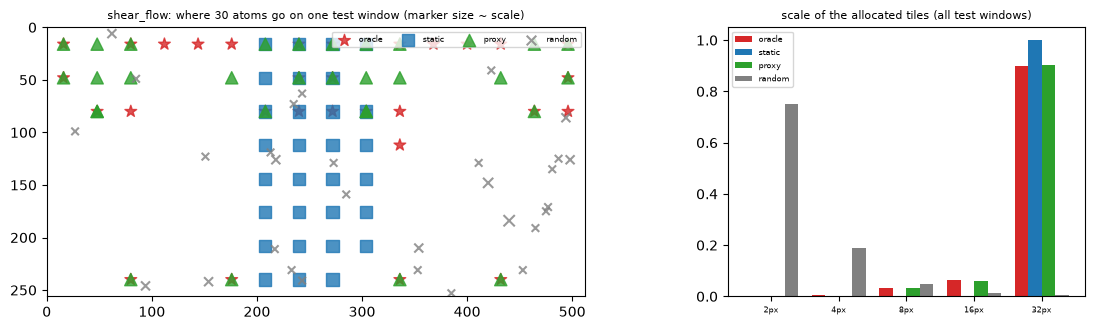

In [16]:
B = 'shear_flow'
alloc = interp.allocation(B)
print('utilization ceilings (share of the trunk error energy reachable by each rule):')
display(pd.Series({k: v for k, v in alloc['ceil'].items() if k == 'dc' or k.endswith('@30') or k.startswith('oracle')}).round(4).to_frame('U').T)
nbviz.allocation_plot(alloc, B); plt.show()

,U,lin gain %,lin captured,mlp gain %,mlp captured,ryd gain %,ryd captured,efficiency ryd
strategy,,,,,,,,
pooled,0.0387,3.4806,0.0298,6.3842,0.0364,6.7668,0.0357,0.9226
static,0.2153,22.3658,0.2083,22.3634,0.2087,22.3608,0.2082,0.9672
proxy,0.3045,26.3179,0.2836,26.3251,0.2856,26.3246,0.2843,0.9338
learned,0.3350,26.2620,0.3150,26.2732,0.3169,26.2921,0.3164,0.9443
gain,0.3324,26.2929,0.3171,26.2168,0.3171,26.2638,0.3175,0.9551
random,0.0003,0.0109,0.0002,0.0100,0.0001,0.0108,0.0002,0.5805
oracle,0.3532,26.4367,0.3310,26.4411,0.3314,26.4369,0.3312,0.9375


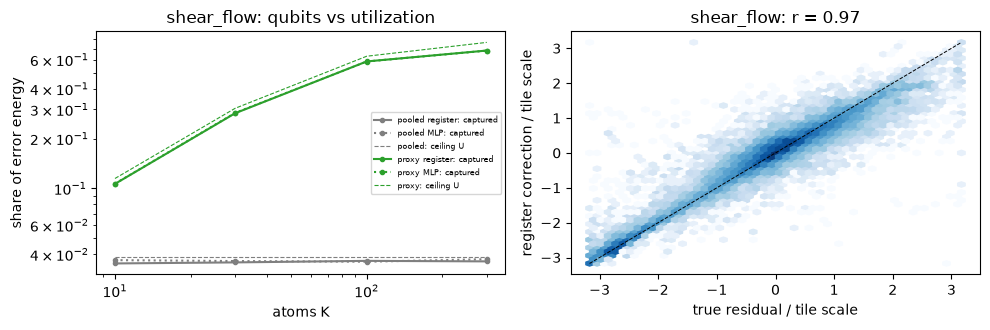

,register vs,strategy,rel. gain %,wins,p
0,mlp,learned,0.0256,3/3,0.0023
1,lin,learned,0.0408,3/3,0.0569
2,gutz,learned,0.0598,3/3,0.0170
3,ryd2d,learned,0.0236,3/3,0.1716
4,mlpX4,learned,0.0116,2/3,0.6548
5,hyb vs mlp2 (division of labour),learned,-0.0138,1/3,0.6620


In [17]:
display(nbviz.row_table(B).round(4))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4)); nbviz.ksweep(B, ax[0])
run, m, st, d = interp.load(B, 'ryd'); x, y = interp.correction_vs_residual(run, m, st)
nbviz.scatter_corr(x, y, B, ax[1]); plt.tight_layout(); plt.show()
display(nbviz.controls(B).round(4))

In [18]:
print('best strategy (VALID):', st)
print('learned analog controls:', interp.register_physics(m))
print('readout usage (share of |A| per observable):', interp.readout_usage(m))
print('register path split:', {k: round(v, 4) for k, v in interp.path_split(run, m, st).items()})
print('entanglement of the trained register on test groups:', {k: round(v, 3) for k, v in interp.entanglement(run, m, st).items()})
run2, m2, _, _ = interp.load(B, 'mlp')
print('matched-MLP path split:', {k: round(v, 4) for k, v in interp.path_split(run2, m2, st).items()})

best strategy (VALID): learned
learned analog controls: {'blockade_scale_px': [4.090000152587891, 6.059999942779541, 4.0], 'scale_plane_dz': 0.43249472975730896, 'drive_omega': [0.1080000028014183, 0.20499999821186066, 0.11500000208616257, 1.1579999923706055], 'evolution_tau': [0.34200000762939453, 0.3529999852180481, 0.3880000114440918, 0.39100000262260437], 'detuning_weight_norm': 2.9129676818847656, 'base_detuning_spread': 0.14828576147556305}
readout usage (share of |A| per observable): {'Z': 0.20600000023841858, 'X': 0.09700000286102295, 'Y': 0.6959999799728394}


register path split: {'core_energy_share': 0.0078, 'captured_full': 0.3171, 'captured_without_core': 0.3067}
entanglement of the trained register on test groups: {'half_entropy_bits_mean': 0.0, 'half_entropy_bits_max': 0.005, 'single_atom_purity_mean': 1.0, 'nn_interaction_mean': 0.667, 'groups': 192}
matched-MLP path split: {'core_energy_share': 0.0485, 'captured_full': 0.3172, 'captured_without_core': 0.2961}


**Interpretation.** The cleanest utilization gradient of the study: random (U 0.0003) → pooled (0.039) → static (0.215) → per-input routing (0.30–0.34), and the captured share tracks U at ~95% efficiency, so the gain follows the allocation almost exactly (+26% vs +3.5–7%). All three cores coincide to four digits: the correction is essentially linear once the atoms are in the right place. With 300 routed atoms, 68% of the error energy is removed.

### 4.4 MHD_64: 3-D magnetohydrodynamic turbulence (fusion)

**Backbone/neck/head:** released 3-D CNextU-net (64³, 7 fields). Flag: released checkpoint scores 0.5447 on our evaluator vs 0.1633 published. **Quantum:** pooled + routed, 3-D Haar tiles (262k per window).

utilization ceilings (share of the trunk error energy reachable by each rule):


,proxy@30,static@30,random@30,oracle@10,oracle@30,oracle@100,oracle@300,dc
U,0.0206,0.0088,0.0001,0.0116,0.0251,0.0544,0.1032,0.002


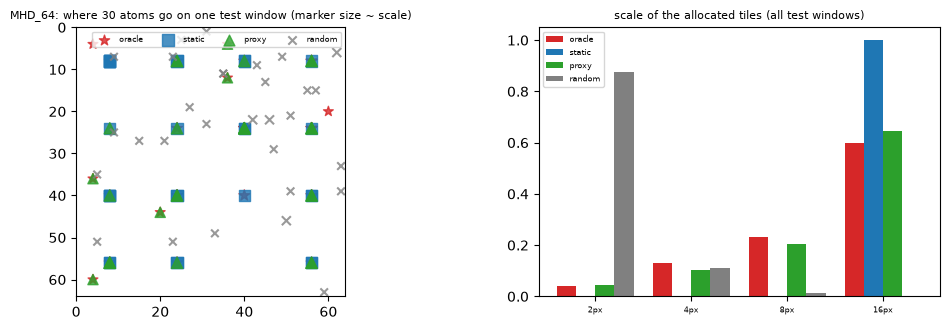

In [19]:
B = 'MHD_64'
alloc = interp.allocation(B)
print('utilization ceilings (share of the trunk error energy reachable by each rule):')
display(pd.Series({k: v for k, v in alloc['ceil'].items() if k == 'dc' or k.endswith('@30') or k.startswith('oracle')}).round(4).to_frame('U').T)
nbviz.allocation_plot(alloc, B); plt.show()

,U,lin gain %,lin captured,mlp gain %,mlp captured,ryd gain %,ryd captured,efficiency ryd
strategy,,,,,,,,
pooled,0.0020,0.1094,0.0020,0.1095,0.0020,0.1099,0.0020,0.9928
static,0.0088,0.3623,0.0082,0.3623,0.0082,0.3623,0.0082,0.9277
proxy,0.0206,0.7673,0.0195,0.7673,0.0195,0.7679,0.0195,0.9483
learned,0.0229,0.8694,0.0219,0.8691,0.0219,0.8694,0.0219,0.9548
gain,0.0229,0.8684,0.0219,0.8666,0.0218,0.8676,0.0219,0.9580
random,0.0001,0.0027,0.0001,0.0028,0.0001,0.0027,0.0001,0.5379
oracle,0.0251,0.9355,0.0236,0.9351,0.0236,0.9353,0.0236,0.9406


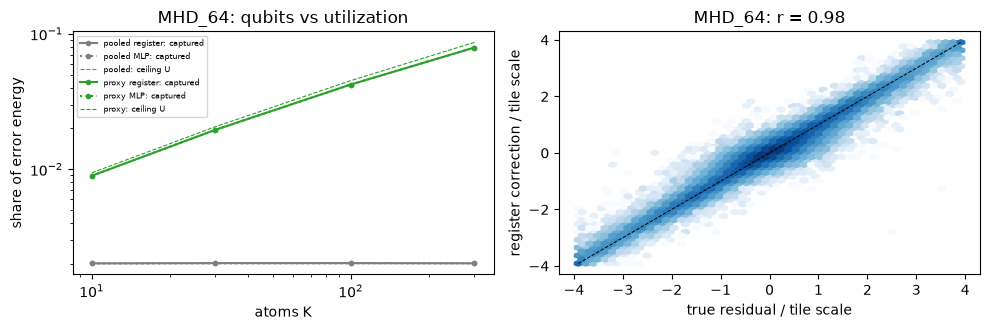

,register vs,strategy,rel. gain %,wins,p
0,mlp,gain,0.0010,1/3,0.5841
1,lin,gain,-0.0008,1/3,0.3407
2,gutz,gain,-0.0008,0/3,0.2144
3,ryd2d,gain,-0.0006,0/3,0.0994
4,mlpX4,gain,-0.0011,0/3,0.1725
5,hyb vs mlp2 (division of labour),gain,-0.0001,2/3,0.7492


In [20]:
display(nbviz.row_table(B).round(4))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4)); nbviz.ksweep(B, ax[0])
run, m, st, d = interp.load(B, 'ryd'); x, y = interp.correction_vs_residual(run, m, st)
nbviz.scatter_corr(x, y, B, ax[1]); plt.tight_layout(); plt.show()
display(nbviz.controls(B).round(4))

In [21]:
print('best strategy (VALID):', st)
print('learned analog controls:', interp.register_physics(m))
print('readout usage (share of |A| per observable):', interp.readout_usage(m))
print('register path split:', {k: round(v, 4) for k, v in interp.path_split(run, m, st).items()})
print('entanglement of the trained register on test groups:', {k: round(v, 3) for k, v in interp.entanglement(run, m, st).items()})
run2, m2, _, _ = interp.load(B, 'mlp')
print('matched-MLP path split:', {k: round(v, 4) for k, v in interp.path_split(run2, m2, st).items()})

best strategy (VALID): gain
learned analog controls: {'blockade_scale_px': [3.7200000286102295, 3.7200000286102295, 3.9700000286102295], 'scale_plane_dz': 1.0425238609313965, 'drive_omega': [0.7250000238418579, 0.6620000004768372, 0.004999999888241291, 0.9039999842643738], 'evolution_tau': [0.29600000381469727, 0.28700000047683716, 0.2800000011920929, 0.29600000381469727], 'detuning_weight_norm': 1.8698958158493042, 'base_detuning_spread': 0.10397850722074509}
readout usage (share of |A| per observable): {'Z': 0.37299999594688416, 'X': 0.3059999942779541, 'Y': 0.32100000977516174}


register path split: {'core_energy_share': 0.0561, 'captured_full': 0.0219, 'captured_without_core': 0.021}
entanglement of the trained register on test groups: {'half_entropy_bits_mean': 0.001, 'half_entropy_bits_max': 0.041, 'single_atom_purity_mean': 0.999, 'nn_interaction_mean': 13.085, 'groups': 192}
matched-MLP path split: {'core_energy_share': 0.2144, 'captured_full': 0.0217, 'captured_without_core': 0.0181}


**Interpretation.** Ceilings are small because the error is spread over 262k tiles (DC 0.2%, 30 routed tiles 2.3%), but what is allocated is captured at ~96%: gain +0.9% with 30 atoms, rising with K (captured 0.9% → 7.9% from 10 to 300 atoms). Cores identical.

### 4.5 RealPDEBench airfoil, released U-Net (real PIV measurements)

**Backbone/neck/head:** RealPDEBench's released U-Net (20→20 frames, 64×128, u,v). **Quantum:** band-limited Fourier corrector (earlier, 1.2%) and routed Haar co-processor (study).

utilization ceilings (share of the trunk error energy reachable by each rule):


,proxy@30,static@30,random@30,oracle@10,oracle@30,oracle@100,oracle@300,dc
U,0.008,0.0173,0.0002,0.0248,0.0543,0.1149,0.2051,0.0067


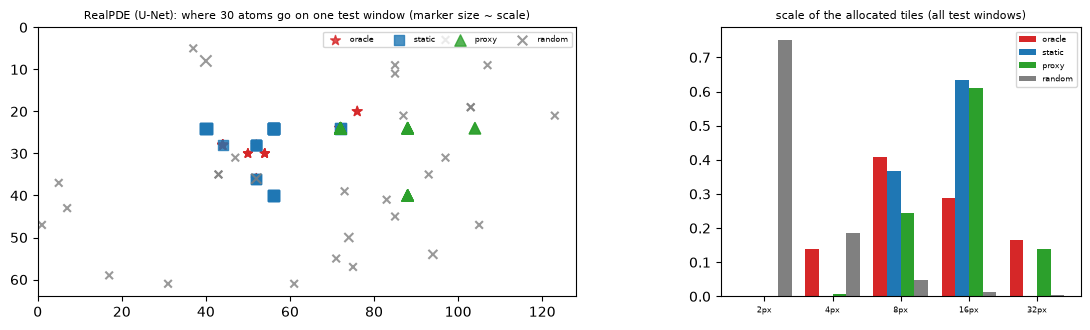

In [22]:
B = 'realpde_unet'
alloc = interp.allocation(B)
print('utilization ceilings (share of the trunk error energy reachable by each rule):')
display(pd.Series({k: v for k, v in alloc['ceil'].items() if k == 'dc' or k.endswith('@30') or k.startswith('oracle')}).round(4).to_frame('U').T)
nbviz.allocation_plot(alloc, B); plt.show()

,U,lin gain %,lin captured,mlp gain %,mlp captured,ryd gain %,ryd captured,efficiency ryd
strategy,,,,,,,,
pooled,0.0067,0.1199,0.0022,0.1232,0.0023,0.1173,0.0022,0.3255
static,0.0173,0.0147,0.0004,0.0170,0.0004,0.0147,0.0004,0.0221
proxy,0.0080,-0.0011,-0.0000,-0.0013,-0.0000,-0.0014,-0.0000,-0.0009
learned,0.0162,0.0078,0.0003,0.0104,0.0004,0.0064,0.0002,0.0148
gain,0.0104,0.0085,0.0003,0.0137,0.0004,0.0102,0.0004,0.0362
random,0.0002,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
oracle,0.0543,0.0335,0.0009,0.0381,0.0010,0.0341,0.0010,0.0176


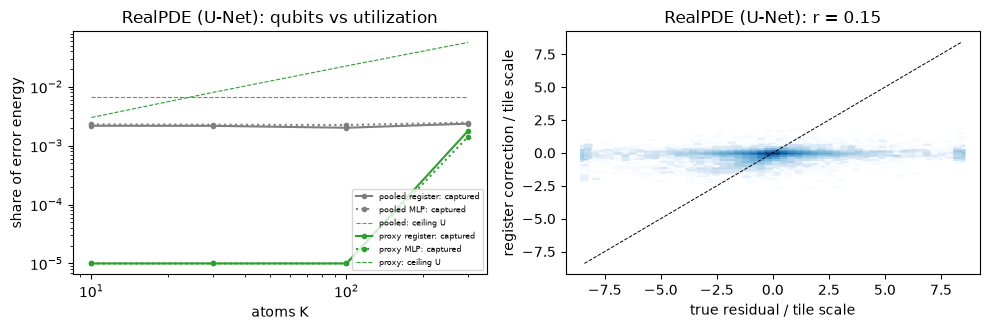

,register vs,strategy,rel. gain %,wins,p
0,mlp,static,-0.0023,0/3,0.0708
1,lin,static,0.0000,2/3,0.9867
2,gutz,static,0.0003,2/3,0.4127
3,ryd2d,static,0.0002,2/3,0.4252
4,mlpX4,static,-0.0046,0/3,0.1173
5,hyb vs mlp2 (division of labour),static,-0.0027,0/3,0.1096


In [23]:
display(nbviz.row_table(B).round(4))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4)); nbviz.ksweep(B, ax[0])
run, m, st, d = interp.load(B, 'ryd'); x, y = interp.correction_vs_residual(run, m, st)
nbviz.scatter_corr(x, y, B, ax[1]); plt.tight_layout(); plt.show()
display(nbviz.controls(B).round(4))

In [24]:
print('best strategy (VALID):', st)
print('learned analog controls:', interp.register_physics(m))
print('readout usage (share of |A| per observable):', interp.readout_usage(m))
print('register path split:', {k: round(v, 4) for k, v in interp.path_split(run, m, st).items()})
print('entanglement of the trained register on test groups:', {k: round(v, 3) for k, v in interp.entanglement(run, m, st).items()})
run2, m2, _, _ = interp.load(B, 'mlp')
print('matched-MLP path split:', {k: round(v, 4) for k, v in interp.path_split(run2, m2, st).items()})

best strategy (VALID): static
learned analog controls: {'blockade_scale_px': [3.559999942779541, 3.559999942779541, 4.059999942779541], 'scale_plane_dz': 1.0979604721069336, 'drive_omega': [0.5379999876022339, 0.5649999976158142, 0.44600000977516174, 0.5270000100135803], 'evolution_tau': [0.21699999272823334, 0.3580000102519989, 0.36500000953674316, 0.3179999887943268], 'detuning_weight_norm': 1.5053870677947998, 'base_detuning_spread': 0.09233005344867706}
readout usage (share of |A| per observable): {'Z': 0.19200000166893005, 'X': 0.4020000100135803, 'Y': 0.4059999883174896}


register path split: {'core_energy_share': 0.0727, 'captured_full': 0.0004, 'captured_without_core': 0.0003}
entanglement of the trained register on test groups: {'half_entropy_bits_mean': 0.521, 'half_entropy_bits_max': 1.48, 'single_atom_purity_mean': 0.83, 'nn_interaction_mean': 57.603, 'groups': 192}
matched-MLP path split: {'core_energy_share': 0.3433, 'captured_full': 0.0004, 'captured_without_core': -0.0001}


**Interpretation.** The U-Net's remaining error is mostly shared across architectures (a measurement-noise floor) and diffuse in space-time; the Haar allocation of 30 tiles reaches only 1.7% of it and captures ~0. The DC part is predictable (+0.12%), and the earlier low-mode Fourier corrector with a much larger block (+1.2%, part of our SoTA ensemble 0.00931) remains the better allocation here: the right basis matters as much as the right tiles.

### 4.6 RealPDEBench airfoil, released FNO

**Backbone/neck/head:** RealPDEBench's released FNO. **Quantum:** routed co-processor (study); earlier low-mode Fourier corrector (−10%).

utilization ceilings (share of the trunk error energy reachable by each rule):


,proxy@30,static@30,random@30,oracle@10,oracle@30,oracle@100,oracle@300,dc
U,0.0452,0.0851,0.0002,0.0453,0.1086,0.2341,0.3617,0.0744


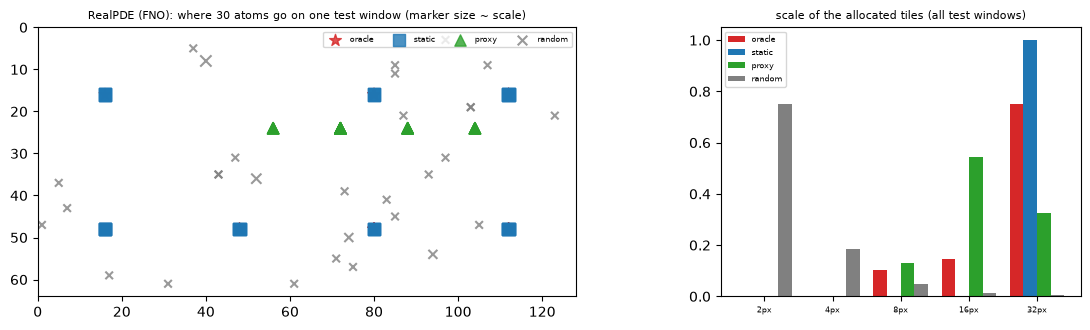

In [25]:
B = 'realpde_fno'
alloc = interp.allocation(B)
print('utilization ceilings (share of the trunk error energy reachable by each rule):')
display(pd.Series({k: v for k, v in alloc['ceil'].items() if k == 'dc' or k.endswith('@30') or k.startswith('oracle')}).round(4).to_frame('U').T)
nbviz.allocation_plot(alloc, B); plt.show()

,U,lin gain %,lin captured,mlp gain %,mlp captured,ryd gain %,ryd captured,efficiency ryd
strategy,,,,,,,,
pooled,0.0744,3.3006,0.0717,3.3221,0.0721,3.3204,0.0721,0.9686
static,0.0851,3.7328,0.0806,3.7427,0.0808,3.7586,0.0812,0.9531
proxy,0.0452,1.2542,0.0309,1.4942,0.0360,1.5181,0.0365,0.8068
learned,0.0913,3.8083,0.0839,3.8298,0.0843,3.8418,0.0845,0.9250
gain,0.0912,3.8339,0.0844,3.8623,0.0849,3.8685,0.0850,0.9322
random,0.0002,0.0014,0.0000,0.0014,0.0000,0.0015,0.0000,0.2073
oracle,0.1086,3.6299,0.0802,3.8824,0.0850,3.9039,0.0853,0.7859


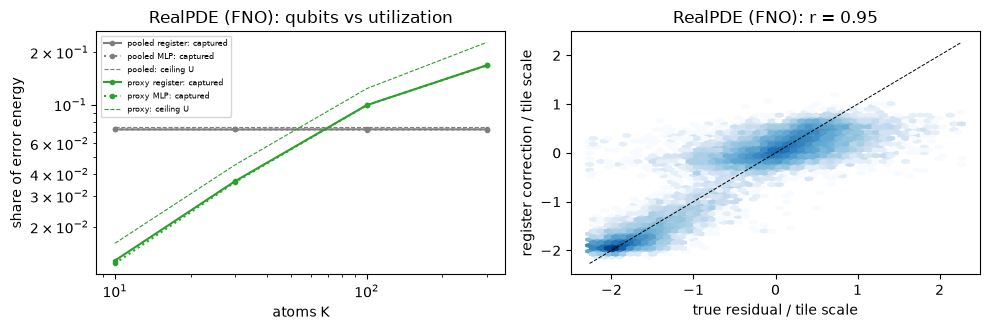

,register vs,strategy,rel. gain %,wins,p
0,mlp,gain,0.0064,3/3,0.1796
1,lin,gain,0.0359,3/3,0.0063
2,gutz,gain,0.0357,3/3,0.0045
3,ryd2d,gain,0.0007,1/3,0.8943
4,mlpX4,gain,0.0005,2/3,0.6951
5,hyb vs mlp2 (division of labour),gain,0.0098,2/3,0.2547


In [26]:
display(nbviz.row_table(B).round(4))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4)); nbviz.ksweep(B, ax[0])
run, m, st, d = interp.load(B, 'ryd'); x, y = interp.correction_vs_residual(run, m, st)
nbviz.scatter_corr(x, y, B, ax[1]); plt.tight_layout(); plt.show()
display(nbviz.controls(B).round(4))

In [27]:
print('best strategy (VALID):', st)
print('learned analog controls:', interp.register_physics(m))
print('readout usage (share of |A| per observable):', interp.readout_usage(m))
print('register path split:', {k: round(v, 4) for k, v in interp.path_split(run, m, st).items()})
print('entanglement of the trained register on test groups:', {k: round(v, 3) for k, v in interp.entanglement(run, m, st).items()})
run2, m2, _, _ = interp.load(B, 'mlp')
print('matched-MLP path split:', {k: round(v, 4) for k, v in interp.path_split(run2, m2, st).items()})

best strategy (VALID): gain
learned analog controls: {'blockade_scale_px': [3.819999933242798, 3.2699999809265137, 4.03000020980835], 'scale_plane_dz': 1.0730869770050049, 'drive_omega': [0.3569999933242798, 0.2759999930858612, 0.3919999897480011, 0.3610000014305115], 'evolution_tau': [0.29100000858306885, 0.28999999165534973, 0.2849999964237213, 0.3009999990463257], 'detuning_weight_norm': 2.1608588695526123, 'base_detuning_spread': 0.2363545149564743}
readout usage (share of |A| per observable): {'Z': 0.11800000071525574, 'X': 0.4690000116825104, 'Y': 0.4129999876022339}


register path split: {'core_energy_share': 0.0536, 'captured_full': 0.085, 'captured_without_core': 0.0825}
entanglement of the trained register on test groups: {'half_entropy_bits_mean': 0.104, 'half_entropy_bits_max': 0.977, 'single_atom_purity_mean': 0.982, 'nn_interaction_mean': 52.683, 'groups': 192}
matched-MLP path split: {'core_energy_share': 0.0514, 'captured_full': 0.085, 'captured_without_core': 0.082}


**Interpretation.** The FNO's sim-to-real bias is systematic and low-frequency: every causal strategy captures ~93% of its ceiling (+3.9% with 30 Haar tiles; the 140-mode Fourier corrector reaches −10%). Register, MLP and linear cores are identical; the gain belongs to the allocation.

### 4.7 Pelzer 1HP heat plume (geothermal)

**Backbone/neck/head:** 1HP_NN U-Net (inputs g,k,s,i → temperature, 256×16), trained by us on 700 maps. **Quantum:** pooled register at the deepest encoder (audit) and routed co-processor (study).

utilization ceilings (share of the trunk error energy reachable by each rule):


,proxy@30,static@30,random@30,oracle@10,oracle@30,oracle@100,oracle@300,dc
U,0.3209,0.4588,0.0116,0.45,0.6473,0.8502,0.9572,0.0471


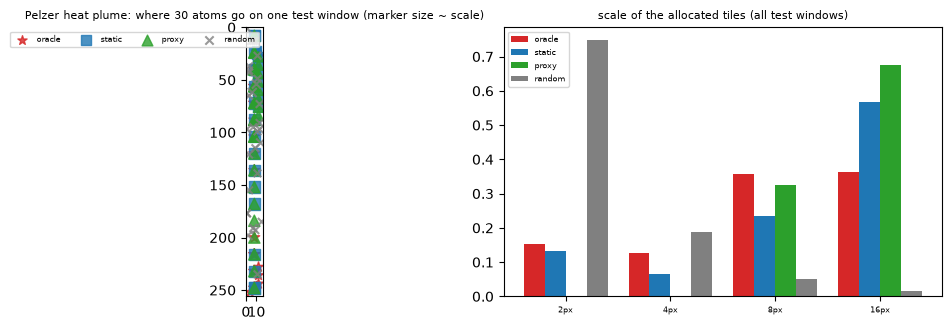

In [28]:
B = 'pelzer'
alloc = interp.allocation(B)
print('utilization ceilings (share of the trunk error energy reachable by each rule):')
display(pd.Series({k: v for k, v in alloc['ceil'].items() if k == 'dc' or k.endswith('@30') or k.startswith('oracle')}).round(4).to_frame('U').T)
nbviz.allocation_plot(alloc, B); plt.show()

,U,lin gain %,lin captured,mlp gain %,mlp captured,ryd gain %,ryd captured,efficiency ryd
strategy,,,,,,,,
pooled,0.0471,1.3241,0.0172,1.3797,0.0177,1.4545,0.0201,0.4257
static,0.4588,8.4329,0.1420,9.3928,0.1569,9.2308,0.1523,0.3319
proxy,0.3209,2.5353,0.0497,3.3282,0.0647,2.7097,0.0530,0.1651
learned,0.4595,6.8724,0.1262,7.9116,0.1433,8.4646,0.1518,0.3304
gain,0.3498,6.6512,0.1182,7.0108,0.1315,7.2402,0.1294,0.3700
random,0.0116,-0.0085,-0.0009,-0.0103,-0.0013,0.0090,-0.0005,-0.0429
oracle,0.6473,14.9377,0.2548,13.3808,0.2287,15.3391,0.2613,0.4036


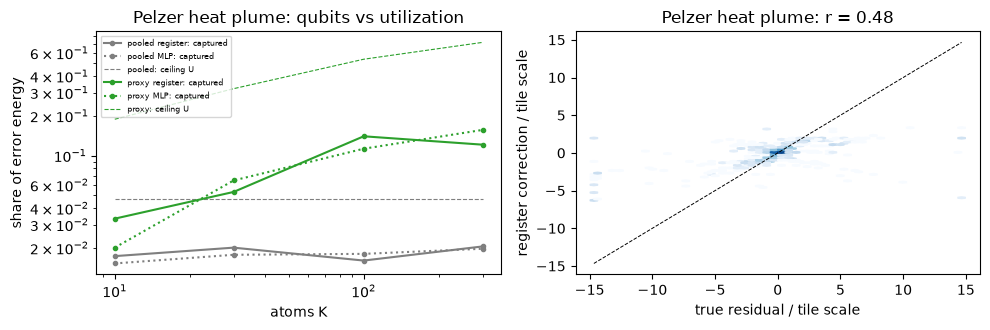

,register vs,strategy,rel. gain %,wins,p
0,mlp,static,-0.1806,1/3,0.6040
1,lin,static,0.8707,3/3,0.0565
2,gutz,static,0.3996,1/3,0.7847
3,ryd2d,static,-0.7389,0/3,0.0189
4,mlpX4,static,-0.1830,1/3,0.7921
5,hyb vs mlp2 (division of labour),static,-0.1480,2/3,0.5654


In [29]:
display(nbviz.row_table(B).round(4))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4)); nbviz.ksweep(B, ax[0])
run, m, st, d = interp.load(B, 'ryd'); x, y = interp.correction_vs_residual(run, m, st)
nbviz.scatter_corr(x, y, B, ax[1]); plt.tight_layout(); plt.show()
display(nbviz.controls(B).round(4))

In [30]:
print('best strategy (VALID):', st)
print('learned analog controls:', interp.register_physics(m))
print('readout usage (share of |A| per observable):', interp.readout_usage(m))
print('register path split:', {k: round(v, 4) for k, v in interp.path_split(run, m, st).items()})
print('entanglement of the trained register on test groups:', {k: round(v, 3) for k, v in interp.entanglement(run, m, st).items()})
run2, m2, _, _ = interp.load(B, 'mlp')
print('matched-MLP path split:', {k: round(v, 4) for k, v in interp.path_split(run2, m2, st).items()})

best strategy (VALID): static
learned analog controls: {'blockade_scale_px': [4.019999980926514, 3.5399999618530273, 4.0], 'scale_plane_dz': 1.1165521144866943, 'drive_omega': [0.5019999742507935, 0.5389999747276306, 0.5149999856948853, 0.5260000228881836], 'evolution_tau': [0.2809999883174896, 0.3190000057220459, 0.3019999861717224, 0.34599998593330383], 'detuning_weight_norm': 1.2155277729034424, 'base_detuning_spread': 0.07375656813383102}
readout usage (share of |A| per observable): {'Z': 0.3089999854564667, 'X': 0.30300000309944153, 'Y': 0.3880000114440918}
register path split: {'core_energy_share': 0.284, 'captured_full': 0.151, 'captured_without_core': 0.0284}
entanglement of the trained register on test groups: {'half_entropy_bits_mean': 0.165, 'half_entropy_bits_max': 0.934, 'single_atom_purity_mean': 0.921, 'nn_interaction_mean': 21.414, 'groups': 192}
matched-MLP path split: {'core_energy_share': 0.1317, 'captured_full': 0.1648, 'captured_without_core': 0.1365}


**Interpretation.** A data-limited trunk leaves a systematic plume-edge error in fixed places: static allocation (+9.2%) is as good as per-input routing, and oracle placement would give +15%. Inside the joint model the register's core carries a larger share of the correction energy than the MLP's core does, yet the end result is no better; the planar register (no scale axis) is slightly better than the 3-D one.

## 5. Benchmarks outside the allocation study

### 5.1 Fusion Equilibrium Challenge (Sophelio, DIII-D)
**Backbone:** residual MLP over coil currents at 14 time lags and Thomson features. **Neck:** latent coupling or a spectral-routed coupling that writes only PCA components k ≥ 8 of the flux (register or matched MLP). **Head:** PCA-64 flux decoder + scalar heads. Interpretation: routing the coupling into the fine flux band lifts VALID S by +0.0012 to +0.0015 with **either** core; the ensemble selected on VALID (with MLP-coupled members) scores TEST 0.9910, 0.0022 below the leader, and the register-coupled selection is lower (0.9905).

In [31]:
s = (ROOT / 'runs/sophelio_sota/status').read_text()
for key in ('CONFIRM_DONE', 'SOPHELIO_TEST_DONE'):
    line = [l for l in s.splitlines() if l.startswith(key)][-1]
    for part in re.findall(r'\[(?:confirm|test)\][^\[]+', line): print(part.strip()[:160])

[confirm] trial 22: register 0.9878 vs matched MLP 0.9876 (delta +0.0002, paired p 0.426, n=3)
[confirm] trial 20: register 0.9878 vs matched MLP 0.9868 (delta +0.0010, paired p 0.030, n=3)
[confirm] trial 13: register 0.9879 vs matched MLP 0.9876 (delta +0.0002, paired p 0.407, n=3)  2026-09-23T14:32:22+03:00
[test] classical: 7 members sigma=0.0 | FULL VALID S 0.9912 | TEST S 0.9910 psi 0.99962 qb 0.9947 dlcfs 0.0145 cons 0.9672 (373 shots)
[test] _reg: 4 members sigma=0.0 | FULL VALID S 0.9910 | TEST S 0.9905 psi 0.99954 qb 0.9943 dlcfs 0.0145 cons 0.9651 (373 shots)
[test] _mlp: 7 members sigma=0.0 | FULL VALID S 0.9913 | TEST S 0.9910 psi 0.99963 qb 0.9946 dlcfs 0.0146 cons 0.9674 (373 shots)  2026-09-23T22:07:02+03:00


### 5.2 TokaMark 1-1 (MAST), TORAX-Bench and the heat plume in the audit
**TokaMark:** TokaMind-Base-v2 transformer backbone; the register wraps each modality head's CLS input (a vector latent, so no pooling limit applies); register 0.1501 vs MLP 0.1504 vs trunk 0.1509; our ensemble 0.1454 is below the 0.140 leader. **TORAX-Bench:** a 1-D spectral net with the register in its `mid` slot; the tuned MLP adapter is best (0.0141) and the register worst (0.0168). Both rows are in the audit table of §3.

### 5.3 TDC ADMET: the 'digital' control (22 endpoints)
**Backbone:** CheMeleon D-MPNN foundation model; **neck:** register (or MLP) after mean aggregation of atom embeddings; **head:** property FFN, then a VALID-selected stack with MapLight(+GNN) CatBoost. Molecules are discrete graphs; the thesis predicts no register benefit here, and there is none.

register better on 9 / 22 endpoints


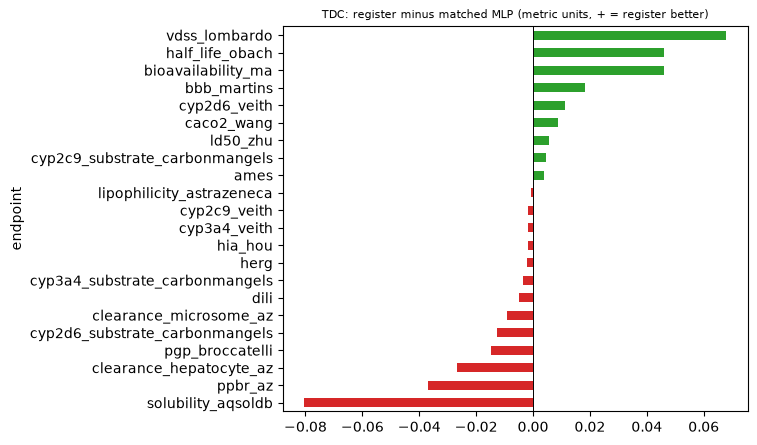

endpoint                         metric                   leader         valsel|vanilla           valsel|mlp30         valsel|mr30ryd         ML+gin|vanilla             ML|vanilla
caco2_wang                       mae       CaliciBoost 0.256±0.006    0.306±0.014 w0.4 #9    0.296±0.008 w0.5 #8    0.304±0.032 w0.4 #9    0.306±0.014 w0.4 #9    0.293±0.013 w0.5 #8
hia_hou                          roc-auc       MiniMol 0.993±0.005    0.989±0.005 w0.7 #3    0.990±0.001 w1.0 #2    0.991±0.003 w0.5 #2    0.991±0.003 w0.7 #2    0.987±0.005 w0.8 #5
pgp_broccatelli                  roc-auc  MapLight + G 0.938±0.002    0.944±0.002 w0.7 #1    0.941±0.003 w0.4 #1    0.942±0.004 w0.8 #1    0.944±0.002 w0.7 #1    0.939±0.002 w0.8 #1
bioavailability_ma               roc-auc       MiniMol 0.942±0.002   0.711±0.007 w0.8 #21   0.709±0.010 w0.7 #21   0.627±0.083 w0.1 #21   0.630±0.086 w0.1 #21   0.726±0.007 w0.6 #21
lipophilicity_astrazeneca        mae           MiniMol 0.456±0.008    0.446±0.008 w0.2 #1   

In [32]:
rows = []
for f in sorted((ROOT / 'runs/tdc_chemeleon').glob('*_mr30ryd.json')):
    ep = f.stem[:-len('_mr30ryd')]; q = json.loads(f.read_text()); mm = ROOT / f'runs/tdc_chemeleon/{ep}_mlp30.json'
    if not mm.exists(): continue
    m_ = json.loads(mm.read_text()); sgn = 1 if q['higher_is_better'] else -1
    rows.append({'endpoint': ep, 'metric': q['metric'], 'register': q['test_mean'], 'matched MLP': m_['test_mean'], 'register better by': sgn * (q['test_mean'] - m_['test_mean'])})
t = pd.DataFrame(rows).set_index('endpoint'); print(f"register better on {(t['register better by'] > 0).sum()} / {len(t)} endpoints")
t['register better by'].sort_values().plot.barh(figsize=(6, 5), color=np.where(t['register better by'].sort_values() > 0, 'C2', 'C3'))
plt.axvline(0, color='k', lw=0.7); plt.title('TDC: register minus matched MLP (metric units, + = register better)', fontsize=8); plt.show()
print((ROOT / 'runs/tdc_ensemble/stack_table.txt').read_text()[:2200])

## 6. Analog vs digital: does the register's inductive bias suit analog maps?

Controlled probe (registered before running): groups of 10 atoms, oscillatory targets $\sin(\omega a)\cos(\omega b)$ (analog) and a sign-product target (digital); test $R^2$, three seeds. Rule: an analog edge needs the register to beat its matched MLP on 3/3 seeds at ≥3 of 5 frequencies. Starred arms (linear-angle register, sine-MLP) are exploratory.

,ryd,gutz,mlp,mlp+,mlpX4,rydlin,mlpsin
analog w=0.5,0.999,0.803,1.000,1.000,1.000,NaN,NaN
analog w=1,0.998,0.971,0.999,1.000,1.000,NaN,NaN
analog w=16,-0.000,NaN,-0.000,-0.000,-0.000,-0.000,-0.000
analog w=2,0.990,0.990,0.979,0.989,0.986,NaN,NaN
analog w=4,0.873,0.642,0.953,0.956,0.989,0.874,0.988
analog w=8,0.000,-0.000,-0.000,-0.000,0.012,-0.000,-0.000
digital,0.067,0.226,0.719,0.920,0.954,NaN,NaN
parity,0.014,0.000,0.055,0.066,0.070,NaN,NaN


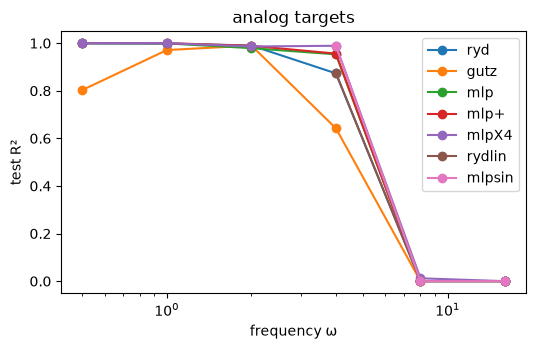

In [33]:
P = nbviz.probe_frame(); display(P)
ax = P.loc[[i for i in P.index if i.startswith('analog')]].rename(index=lambda s: float(s.split('=')[1])).sort_index().plot(marker='o', figsize=(6, 3.4))
ax.set(xscale='log', xlabel='frequency ω', ylabel='test R²', title='analog targets'); plt.show()

**Interpretation.** The register's function class is smooth: it cannot draw thresholds (digital $R^2$ 0.07 vs 0.72–0.95 for MLPs), which supports sending digital structure to classical cores. But it is not better on smooth oscillatory maps: it wins only at ω = 2, trails at ω ≤ 1 and ω = 4, and every core fails at ω ≥ 8. The registered analog-edge rule is not met.

## 7. Synthesis

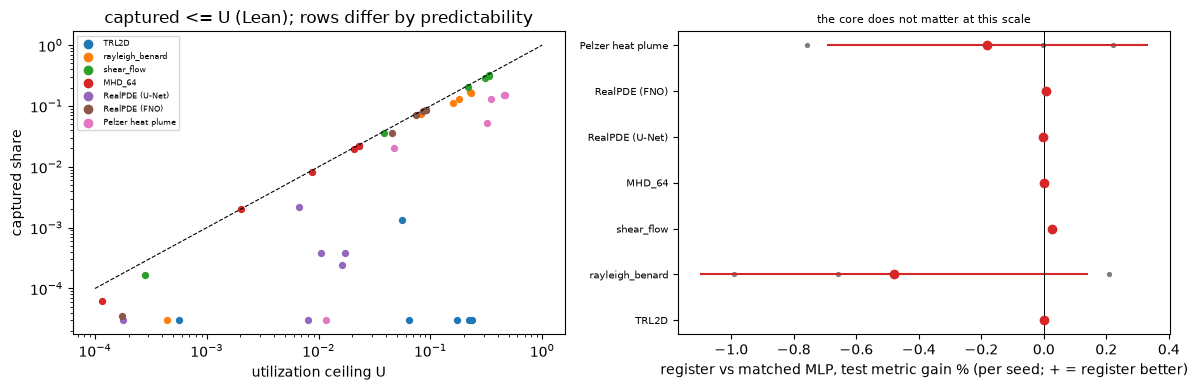

: utilization governs the gain

- lin: Spearman(U, captured) over 42 (bench x strategy) cells = 0.70 [bench-bootstrap 95% CI 0.10, 0.98]
- mlp: Spearman(U, captured) over 42 (bench x strategy) cells = 0.71 [bench-bootstrap 95% CI 0.17, 0.98]
- ryd: Spearman(U, captured) over 42 (bench x strategy) cells = 0.71 [bench-bootstrap 95% CI 0.18, 0.98]
- mlp: causal routing <= pooled on 5/7 benchmarks (P2); gain routing <= energy routing on 3/7 (P4)
- ryd: causal routing <= pooled on 5/7 benchmarks (P2); gain routing <= energy routing on 3/7 (P4)

# H_Q: register vs matched MLP at each benchmark's VALID-best tile strategy

- ryd vs mlp: better/worse 3/3 (sign p=1.00); random-effects +0.006% [-0.005, +0.017], I2=98%
  - TRL2D (static): +0.000% (0/3)
  - rayleigh_benard (proxy): -0.479% (1/3)
  - shear_flow (learned): +0.026% (3/3)
  - RealPDE (U-Net) (static): -0.002% (0/3)
  - RealPDE (FNO) (gain): +0.006% (3/3)
  - pelzer (static): -0.181% (1/3)
  - MHD_64 (gain): +0.001% (1/3)
- ryd vs lin: 

In [34]:
R = analyze.load(); fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for i, b in enumerate(nbviz.NAMES):
    for s in analyze.STRATS:
        v = R[(b, s, 'ryd', 30)]
        if v: ax[0].scatter(analyze.mean([x['test_U'] for x in v]), max(3e-5, analyze.mean([x['test_captured'] for x in v])), color=f'C{i}', s=18)
    ax[0].scatter([], [], color=f'C{i}', label=nbviz.NAMES[b])
ax[0].plot([1e-4, 1], [1e-4, 1], 'k--', lw=0.8); ax[0].set(xscale='log', yscale='log', xlabel='utilization ceiling U', ylabel='captured share', title='captured <= U (Lean); rows differ by predictability')
ax[0].legend(fontsize=6); nbviz.forest(ax[1]); plt.tight_layout(); plt.show()
print(open(ROOT / 'runs/alloc/summary.md').read().split('# H_U')[1][:1500])

**What the model does, benchmark by benchmark, in one sentence each.** A frozen SoTA trunk leaves an error that is either *predictable* (systematic bias: convection onset, sim-to-real FNO bias, a data-limited plume model, miscalibrated released checkpoints) or *not* (fine-scale turbulence of a well-trained trunk). Where it is predictable, placing the atoms on the right tiles turns a fixed budget of 30 atoms into gains of 1–36%, and more atoms keep paying; the pooled neck insertion cannot, whatever its size, exactly as the Lean bounds say. Where it is not, no allocation and no core helps. In every row the Rydberg register does this job as well as, and no better than, a parameter-matched classical core; its one register-specific effect remains the training-mediated long-horizon gain on TRL2D. **Utilization, not qubit count, decides the hybrid gain.**